# 01 Profiling
Checks the loaded data before any conclusions are drawn: how many sales there are each month, how prices are spread, what kinds of property sold, which councils have too few sales, and how much data was rejected. 

Note: Everything here only reads from the database.

In [1]:
import sys
sys.path.append("..")  # lets the notebook import from the pipeline package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pipeline.db import get_engine

engine = get_engine()
pd.read_sql("select count(*) from core.fact_sale", engine)

,count
0,5633489


## Sales per month
**Expect:** roughly 70,000 to 90,000 sales a month, a sharp dip in April to June 2020 (the first lockdown), and spikes in March and June 2021 just before the stamp duty holiday deadlines.

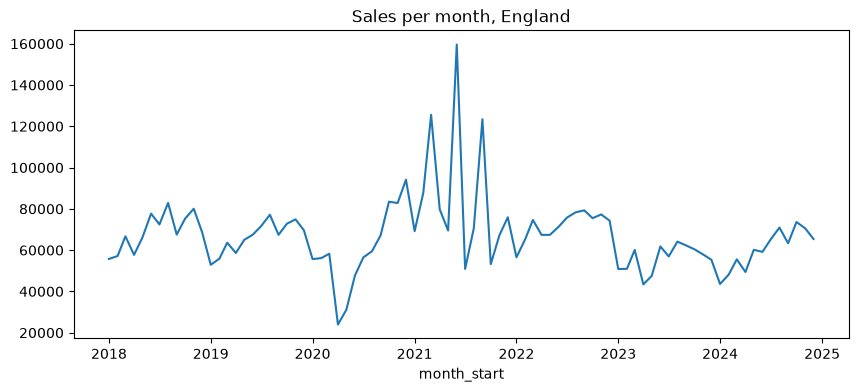

In [2]:
monthly = pd.read_sql("""
    select month_start, sum(sales) as sales
    from mart.council_month group by 1 order by 1
""", engine)
monthly.plot(x="month_start", y="sales", figsize=(10, 4), legend=False, title="Sales per month, England")
plt.show()

**Saw:** a normal month in 2019 averaged about 66,400 sales. April 2020 fell to 23,974, the lowest month in the data. The highest months were June 2021 (159,627) and March 2021 (125,567), the two stamp duty deadlines, with September 2021 (123,432) close behind as the taper ended.

**So what:** the data reflects real events, which is good evidence the load is complete: a missing file would show as a gap, not a dip. Figures for 2020 and 2021 are distorted by policy.

______________________________________________________________________________________________________________________________

## Price spread
**Expect:** a skewed distribution with most sales between £100,000 and £500,000 (4.9 to 5.7 on the log scale), a long tail of expensive sales, and only a few hundred outliers under £10,000 or over £10 million each year.

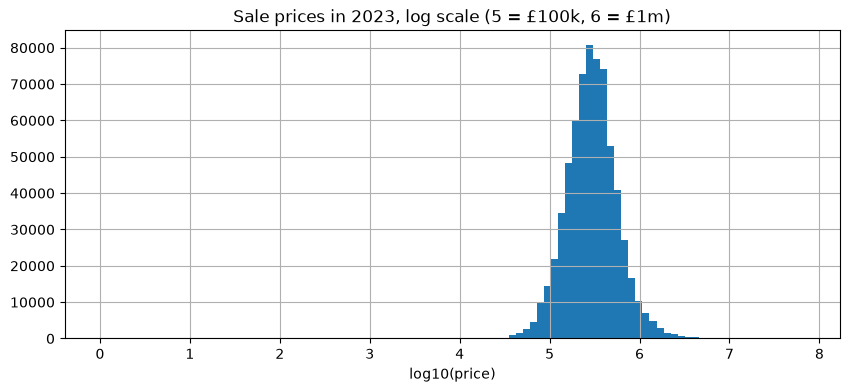

,year,outliers,sales
0,2018,87,827953
1,2019,114,797083
2,2020,96,716291
3,2021,124,1032563
4,2022,163,862778
5,2023,153,671654
6,2024,124,725167


In [3]:
YEAR = 2023
prices = pd.read_sql(
    """
    select f.price, f.is_outlier
    from core.fact_sale f join core.dim_date d on d.date_key = f.date_key
    where d.year = %(year)s
    """,
    engine,
    params={"year": YEAR},
)
np.log10(prices["price"]).hist(bins=100, figsize=(10, 4))
plt.title(f"Sale prices in {YEAR}, log scale (5 = £100k, 6 = £1m)")
plt.xlabel("log10(price)")
plt.show()

outliers = pd.read_sql("""
    select d.year, count(*) filter (where f.is_outlier) as outliers, count(*) as sales
    from core.fact_sale f join core.dim_date d on d.date_key = f.date_key
    group by 1 order by 1
""", engine)
outliers

**Saw:** in 2023 the log-scale histogram is a single smooth hump centred around 5.45 (median £292,500), with a thin tail above 6 (£1m+). Outliers are about 0.02% of sales every year, between 87 and 163 a year, 861 in total.

**So what:** outliers are too rare to move a median, so I keep them flagged rather than deleting them. A log scale is the right way to show prices in any chart.

______________________________________________________________________________________________________________________________

## Property mix by year
**Expect:** terraced and semi-detached houses each around a quarter to a third of sales, flats around a fifth, and a shift towards houses in 2020 and 2021, when buyers wanted more space.

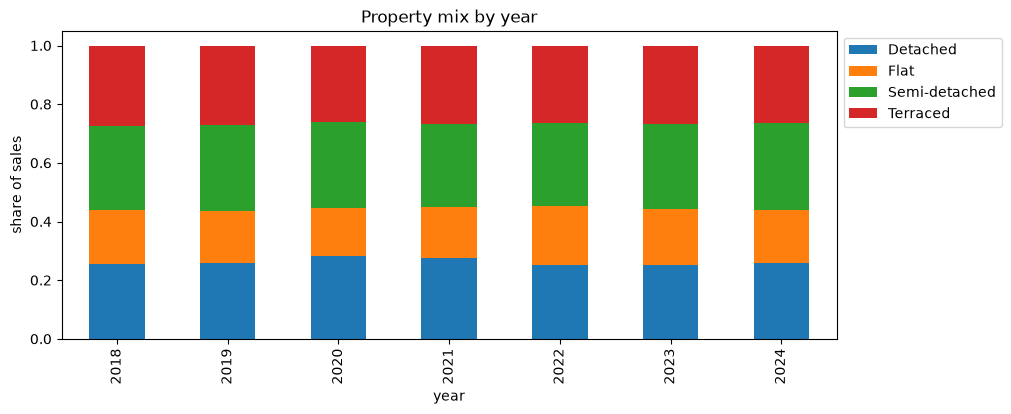

type_label,Detached,Flat,Semi-detached,Terraced
year,,,,
2018,0.254,0.187,0.287,0.273
2019,0.260,0.177,0.293,0.270
2020,0.281,0.166,0.292,0.261
2021,0.276,0.172,0.286,0.266
2022,0.251,0.200,0.283,0.265
2023,0.250,0.194,0.290,0.266
2024,0.259,0.180,0.297,0.264


In [4]:
mix = pd.read_sql("""
    select d.year, p.type_label, count(*) as sales
    from core.fact_sale f
    join core.dim_date d     on d.date_key = f.date_key
    join core.dim_property p on p.property_key = f.property_key
    group by 1, 2
""", engine)
counts = mix.pivot(index="year", columns="type_label", values="sales").fillna(0)
shares = counts.div(counts.sum(axis=1), axis=0)
shares.plot(kind="bar", stacked=True, figsize=(10, 4), title="Property mix by year")
plt.ylabel("share of sales")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()
shares.round(3)

**Saw:** the mix is stable: semis 28–30%, terraces 26–27%, detached 25–28%, flats 17–20%. The biggest swing is 2020, when detached rose to 28.1% and flats fell to 16.6% (the race for space during lockdown). By 2022 flats were back up to 20.0%.

**So what:** part of the 2020–21 price rise is composition: more big houses sold, not just higher prices. This is the composition effect, and it goes in the limitations.

______________________________________________________________________________________________________________________________

## Low-volume councils
**Expect:** only a handful of councils with under 300 sales in a year, mainly the City of London and the Isles of Scilly.

In [5]:
low = pd.read_sql("""
    select ons_year, council_name, sales
    from mart.council_year
    where low_volume
    order by ons_year, sales
""", engine)
print(low.groupby("ons_year").size())
low

ons_year
2019    2
2020    2
2021    2
2022    2
2023    2
2024    2
dtype: int64


,ons_year,council_name,sales
0,2019,Isles of Scilly,22
1,2019,City of London,186
2,2020,Isles of Scilly,16
3,2020,City of London,136
4,2021,Isles of Scilly,29
5,2021,City of London,245
6,2022,Isles of Scilly,10
7,2022,City of London,196
8,2023,Isles of Scilly,10
9,2023,City of London,162


**Saw:** exactly two councils are flagged, in every ONS year from 2019 to 2024: the Isles of Scilly (10–29 sales a year) and the City of London (136–245). No other council is flagged.

**So what:** they're left out of the rankings in 02_analysis but kept in totals, because a median of a few dozen sales jumps around too much to compare.

______________________________________________________________________________________________________________________________

## Data quality
**Expect:** every raw row accounted for (kept plus rejected equals loaded), most rejects being category B sales, and most council-years within 2% of the ONS median price.

In [6]:
loaded = pd.read_sql("select count(*) as n from raw.price_paid", engine).n[0]
rejected = pd.read_sql("select reason, count(*) as n from staging.sales_rejected group by 1 order by 2 desc", engine)
outlier_count = pd.read_sql("select count(*) as n from core.fact_sale where is_outlier", engine).n[0]
manual = pd.read_sql("select count(*) as n from staging.district_map where match_type = 'manual'", engine).n[0]
pass_rate = pd.read_sql("""
    select round(100.0 * count(*) filter (where abs(pct_diff) <= 2) / count(*), 1) as pct
    from mart.council_year where pct_diff is not null
""", engine).pct[0]

rows = [("Rows loaded from Land Registry", f"{loaded:,}")]
rows += [(f"Rejected: {r.reason}", f"{r.n:,}") for r in rejected.itertuples()]
rows += [
    ("Kept but flagged as outliers", f"{outlier_count:,}"),
    ("Districts mapped by hand (seed file)", f"{manual:,}"),
    ("Council-years within 2% of ONS median", f"{pass_rate}%"),
]
quality = pd.DataFrame(rows, columns=["Measure", "Value"])
print(quality.to_markdown(index=False))

| Measure                               | Value     |
|:--------------------------------------|:----------|
| Rows loaded from Land Registry        | 7,100,023 |
| Rejected: category B                  | 1,158,957 |
| Rejected: Wales                       | 307,577   |
| Kept but flagged as outliers          | 861       |
| Districts mapped by hand (seed file)  | 46        |
| Council-years within 2% of ONS median | 99.7%     |


**Saw:** 7,100,023 rows loaded. 1,158,957 rejected as category B (repossessions, buy-to-let and other non-standard sales) and 307,577 as Welsh sales (out of scope). No rows rejected for bad prices or dates. 861 kept sales flagged as outliers, 46 districts mapped by hand. 99.7% of council-years (1,770 of 1,776) are within 2% of the ONS median price.

**So what:** I calculated every median myself from the raw sales and matched the official ONS figure in 99.7% of council-years. That means the cleaning, rejecting and district matching didn't distort anything, and I can trust everything built on top. The 6 that don't match are worth looking at before I rely on those councils.